<a href="https://colab.research.google.com/github/ali-liyakat/100_days_Deep_Learning/blob/main/06_CNN/09_Functional_API.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CNN Using Keras Functional API — Dogs vs Cats

This notebook implements a Convolutional Neural Network (CNN) using TensorFlow and Keras Functional API to classify images of cats and dogs.

**Objectives:**
- Understand the Keras Functional API and its difference from the Sequential API.
- Build a CNN using explicit input and output tensors.
- Train and evaluate the model on the Dogs vs Cats dataset.
- Visualize the model architecture, training performance, and predictions.

In [5]:
%pip install -q kagglehub

In [6]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import layers, Model
from pathlib import Path

print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPUs: []


In [7]:
import kagglehub
from pathlib import Path

dataset_path = Path(
    kagglehub.dataset_download("salader/dogsvscats")
)

print("Dataset path:", dataset_path)
print("Contents:", [p.name for p in dataset_path.iterdir()])

Using Colab cache for faster access to the 'dogsvscats' dataset.
Dataset path: /kaggle/input/dogsvscats
Contents: ['test', 'train', 'catsvsdogs']


In [8]:
from pathlib import Path

train_matches = list(dataset_path.rglob("train"))
test_matches = list(dataset_path.rglob("test"))

print("Training folders:", train_matches)
print("Testing folders:", test_matches)

Training folders: [PosixPath('/kaggle/input/dogsvscats/train'), PosixPath('/kaggle/input/dogsvscats/catsvsdogs/train')]
Testing folders: [PosixPath('/kaggle/input/dogsvscats/test'), PosixPath('/kaggle/input/dogsvscats/catsvsdogs/test')]


In [9]:
train_dir = next(
    p for p in train_matches
    if (p / "cats").is_dir() and (p / "dogs").is_dir()
)

test_dir = next(
    p for p in test_matches
    if (p / "cats").is_dir() and (p / "dogs").is_dir()
)

print("Train directory:", train_dir)
print("Test directory:", test_dir)
print("Train exists:", train_dir.exists())
print("Test exists:", test_dir.exists())

Train directory: /kaggle/input/dogsvscats/train
Test directory: /kaggle/input/dogsvscats/test
Train exists: True
Test exists: True


In [10]:
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_names=["cats", "dogs"],
    label_mode="binary"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_names=["cats", "dogs"],
    label_mode="binary"
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_names=["cats", "dogs"],
    label_mode="binary",
    shuffle=False
)

class_names = ["cats", "dogs"]

Found 20000 files belonging to 2 classes.
Using 16000 files for training.
Found 20000 files belonging to 2 classes.
Using 4000 files for validation.
Found 5000 files belonging to 2 classes.


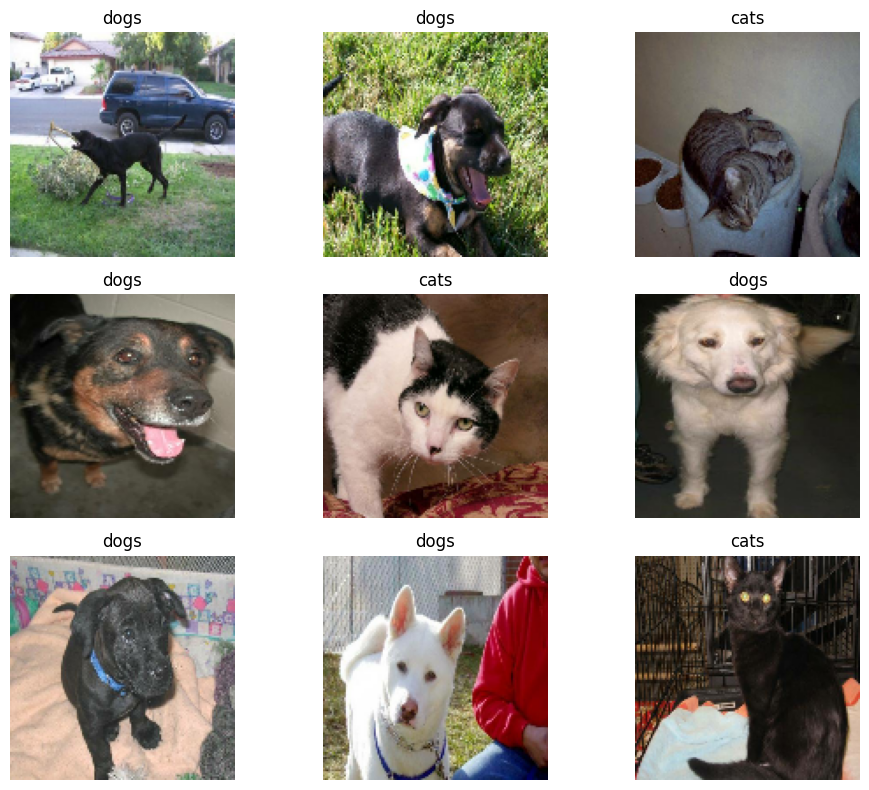

In [11]:
plt.figure(figsize=(10, 8))

for images, labels in train_ds.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i].numpy()[0])])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [12]:
inputs = layers.Input(shape=(128, 128, 3), name="image_input")

# Normalize pixel values
x = layers.Rescaling(1./255)(inputs)

# Convolutional block 1
x = layers.Conv2D(32, (3, 3), activation="relu", padding="same")(x)
x = layers.MaxPooling2D((2, 2))(x)

# Convolutional block 2
x = layers.Conv2D(64, (3, 3), activation="relu", padding="same")(x)
x = layers.MaxPooling2D((2, 2))(x)

# Convolutional block 3
x = layers.Conv2D(128, (3, 3), activation="relu", padding="same")(x)
x = layers.MaxPooling2D((2, 2))(x)

# Classification head
x = layers.Flatten()(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.5)(x)

outputs = layers.Dense(1, activation="sigmoid", name="prediction")(x)

model = Model(inputs=inputs, outputs=outputs, name="functional_cnn")

model.summary()

Model: "functional_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image_input (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ prediction (Dense)              │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,287,809 (16.36 MB)

 Trainable params: 4,287,809 (16.36 MB)

 Non-trainable params: 0 (0.00 B)

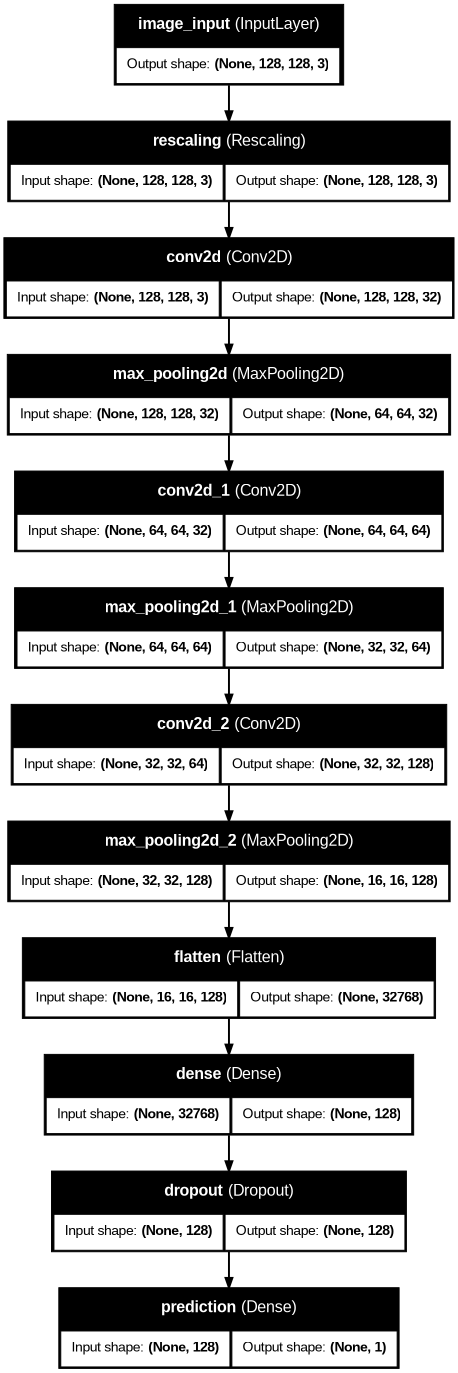

In [13]:
tf.keras.utils.plot_model(
    model,
    show_shapes=True,
    show_layer_names=True,
    expand_nested=True,
    dpi=70
)

In [14]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [15]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 612s 1s/step - accuracy: 0.6199 - loss: 0.6393 - val_accuracy: 0.7097 - val_loss: 0.5574
Epoch 2/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 652s 1s/step - accuracy: 0.7203 - loss: 0.5487 - val_accuracy: 0.7615 - val_loss: 0.4963
Epoch 3/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 622s 1s/step - accuracy: 0.7816 - loss: 0.4682 - val_accuracy: 0.7755 - val_loss: 0.4650
Epoch 4/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 622s 1s/step - accuracy: 0.8114 - loss: 0.4139 - val_accuracy: 0.7958 - val_loss: 0.4434
Epoch 5/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 641s 1s/step - accuracy: 0.8391 - loss: 0.3622 - val_accuracy: 0.8110 - val_loss: 0.4045
Epoch 6/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 674s 1s/step - accuracy: 0.8720 - loss: 0.2986 - val_accuracy: 0.8160 - val_loss: 0.4647
Epoch 7/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 626s 1s/step - accuracy: 0.8986 - loss: 0.2475 - val_accuracy: 0.8100 - val_loss: 0.4936
Epoch 8/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 622s 1s/step - accuracy: 0.9182 - loss: 0.2018 - val_accu

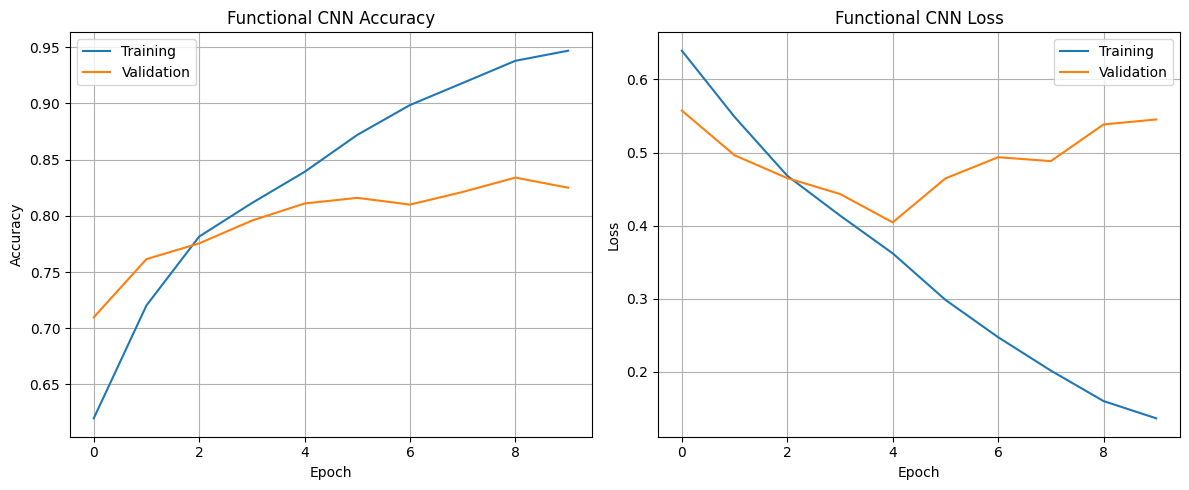

In [16]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Functional CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Functional CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [17]:
test_loss, test_accuracy = model.evaluate(test_ds)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

157/157 ━━━━━━━━━━━━━━━━━━━━ 54s 345ms/step - accuracy: 0.8326 - loss: 0.4989
Test Loss: 0.4989
Test Accuracy: 83.26%


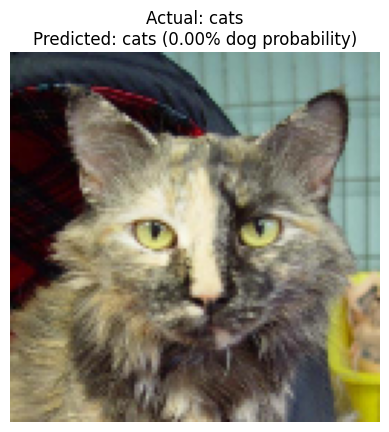

In [18]:
for images, labels in test_ds.take(1):
    image = images[0]
    true_label = int(labels[0].numpy()[0])

    prediction = model.predict(
        tf.expand_dims(image, axis=0),
        verbose=0
    )[0][0]

    predicted_label = 1 if prediction >= 0.5 else 0

    plt.imshow(image.numpy().astype("uint8"))
    plt.title(
        f"Actual: {class_names[true_label]}\n"
        f"Predicted: {class_names[predicted_label]} "
        f"({prediction:.2%} dog probability)"
    )
    plt.axis("off")
    plt.show()